<div style="padding:18px 22px;border-radius:8px">
<h1>UCS420 · Cognitive Computing</h1>
<h3 style="margin:6px 0 0 0;color:#ffffff">Lab Assignment 10 — NLP using Python-II</h3>
<p style="margin:4px 0 0 0;color:#ffffff">Feature extraction from text, sentiment analysis and text generation</p>
</div>

| | |
|---|---|
| **Name** | Waris |
| **Roll No.** | 1024170155 |

### Environment setup
Installs anything missing and downloads the NLTK resources only when they are not already on the machine.

In [2]:
import importlib, subprocess, sys

packages = {"nltk": "nltk", "sklearn": "scikit-learn", "textblob": "textblob",
            "wordcloud": "wordcloud", "tensorflow": "tensorflow",
            "pandas": "pandas", "matplotlib": "matplotlib"}
to_install = [pip for mod, pip in packages.items() if importlib.util.find_spec(mod) is None]
if to_install:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *to_install])
print("Missing packages installed:" if to_install else "Environment OK — nothing to install.", to_install or "")

import nltk
for res, path in [("punkt", "tokenizers/punkt"), ("punkt_tab", "tokenizers/punkt_tab"),
                  ("stopwords", "corpora/stopwords"), ("wordnet", "corpora/wordnet"),
                  ("omw-1.4", "corpora/omw-1.4"), ("vader_lexicon", "sentiment/vader_lexicon.zip"),
                  ("averaged_perceptron_tagger_eng", "taggers/averaged_perceptron_tagger_eng")]:
    try:
        nltk.data.find(path)
    except LookupError:
        nltk.download(res, quiet=True)
print("NLTK data ready.")

Environment OK — nothing to install. 


[nltk_data] Error loading wordnet: <urlopen error [Errno 54]
[nltk_data]     Connection reset by peer>


NLTK data ready.


[nltk_data] Error loading omw-1.4: <urlopen error [Errno 54]
[nltk_data]     Connection reset by peer>


In [3]:
import re, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.probability import FreqDist
from nltk.stem import PorterStemmer, WordNetLemmatizer

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

# RCB-inspired palette used for every chart in this notebook
RED, GOLD, BLACK, GREY = "#B3001B", "#FFB000", "#1A1A1A", "#9E9E9E"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "figure.dpi": 100})

EN_STOP = set(stopwords.words("english"))
print("Stopword list size:", len(EN_STOP))

Stopword list size: 198


---
# Question 1
> **Q1. Write a unique paragraph (5–6 sentences) about your favorite topic (e.g., sports, technology, food, books, etc.).**
> 1. Convert text to lowercase and remove punctuation using `re`.
> 2. Tokenize the text into words and sentences.
> 3. Split using `split()` and `word_tokenize()` and compare how Python split and NLTK's `word_tokenize()` differ.
> 4. Remove stopwords (using NLTK's stopwords list).
> 5. Display word frequency distribution (excluding stopwords).

## Answer 1

**Paragraph (topic: Virat Kohli, 6 sentences).**

In [4]:
kohli_para = (
    "Virat Kohli is one of the greatest batters in the history of cricket, and his hunger for runs "
    "is what sets him apart. "
    "Born in Delhi in 1988, Kohli captained India to the Under-19 World Cup title in 2008 and made "
    "his ODI debut later that year. "
    "Over the next decade, Kohli turned chasing into an art; his cover drive, sharp running between "
    "the wickets and calm temperament won India countless matches. "
    "In the 2023 World Cup semi-final, he scored his 50th ODI century, breaking Sachin Tendulkar's "
    "record of 49 ODI centuries. "
    "He finally lifted the IPL trophy with RCB in 2025, after 18 seasons with the same franchise. "
    "Kohli's fitness revolution didn't just change his own game - it raised the fitness standards "
    "of the entire Indian team."
)
print(kohli_para)
print(f"\nLength: {len(kohli_para)} characters, {len(kohli_para.split())} whitespace-separated words")

Virat Kohli is one of the greatest batters in the history of cricket, and his hunger for runs is what sets him apart. Born in Delhi in 1988, Kohli captained India to the Under-19 World Cup title in 2008 and made his ODI debut later that year. Over the next decade, Kohli turned chasing into an art; his cover drive, sharp running between the wickets and calm temperament won India countless matches. In the 2023 World Cup semi-final, he scored his 50th ODI century, breaking Sachin Tendulkar's record of 49 ODI centuries. He finally lifted the IPL trophy with RCB in 2025, after 18 seasons with the same franchise. Kohli's fitness revolution didn't just change his own game - it raised the fitness standards of the entire Indian team.

Length: 734 characters, 129 whitespace-separated words


### 1.1 Convert to lowercase and remove punctuation using `re`
**Answer:** `str.lower()` handles case; `re.sub(r"[^a-z0-9\s]", " ", …)` replaces every character that is not a letter, digit or space. Replacing with a **space** (instead of deleting) keeps `under-19` as two words (`under 19`) rather than the meaningless `under19`.

In [5]:
lowered = kohli_para.lower()
no_punct = re.sub(r"[^a-z0-9\s]", " ", lowered)
no_punct = re.sub(r"\s+", " ", no_punct).strip()

punct_found = Counter(ch for ch in kohli_para if re.match(r"[^\w\s]", ch))
print("Punctuation removed:", dict(punct_found))
print("\nCleaned text:\n", no_punct)

Punctuation removed: {',': 7, '.': 6, '-': 3, ';': 1, "'": 3}

Cleaned text:
 virat kohli is one of the greatest batters in the history of cricket and his hunger for runs is what sets him apart born in delhi in 1988 kohli captained india to the under 19 world cup title in 2008 and made his odi debut later that year over the next decade kohli turned chasing into an art his cover drive sharp running between the wickets and calm temperament won india countless matches in the 2023 world cup semi final he scored his 50th odi century breaking sachin tendulkar s record of 49 odi centuries he finally lifted the ipl trophy with rcb in 2025 after 18 seasons with the same franchise kohli s fitness revolution didn t just change his own game it raised the fitness standards of the entire indian team


### 1.2 Tokenize into words and sentences
**Answer:** Sentences are tokenized from the original paragraph, because cleaning removes the full stops that `sent_tokenize()` needs. Words are tokenized from the cleaned text.

In [6]:
sent_tokens = sent_tokenize(kohli_para)
word_tokens = word_tokenize(no_punct)

sent_table = pd.DataFrame({"Sentence": sent_tokens,
                           "Words": [len(word_tokenize(s)) for s in sent_tokens]},
                          index=[f"S{i}" for i in range(1, len(sent_tokens) + 1)])
display(sent_table)
print(f"Total sentences: {len(sent_tokens)} | total word tokens: {len(word_tokens)}")
print(word_tokens)

,Sentence,Words
S1,Virat Kohli is one of the greatest batters in ...,25
S2,"Born in Delhi in 1988, Kohli captained India t...",26
S3,"Over the next decade, Kohli turned chasing int...",29
S4,"In the 2023 World Cup semi-final, he scored hi...",24
S5,He finally lifted the IPL trophy with RCB in 2...,19
S6,Kohli's fitness revolution didn't just change ...,23


Total sentences: 6 | total word tokens: 133
['virat', 'kohli', 'is', 'one', 'of', 'the', 'greatest', 'batters', 'in', 'the', 'history', 'of', 'cricket', 'and', 'his', 'hunger', 'for', 'runs', 'is', 'what', 'sets', 'him', 'apart', 'born', 'in', 'delhi', 'in', '1988', 'kohli', 'captained', 'india', 'to', 'the', 'under', '19', 'world', 'cup', 'title', 'in', '2008', 'and', 'made', 'his', 'odi', 'debut', 'later', 'that', 'year', 'over', 'the', 'next', 'decade', 'kohli', 'turned', 'chasing', 'into', 'an', 'art', 'his', 'cover', 'drive', 'sharp', 'running', 'between', 'the', 'wickets', 'and', 'calm', 'temperament', 'won', 'india', 'countless', 'matches', 'in', 'the', '2023', 'world', 'cup', 'semi', 'final', 'he', 'scored', 'his', '50th', 'odi', 'century', 'breaking', 'sachin', 'tendulkar', 's', 'record', 'of', '49', 'odi', 'centuries', 'he', 'finally', 'lifted', 'the', 'ipl', 'trophy', 'with', 'rcb', 'in', '2025', 'after', '18', 'seasons', 'with', 'the', 'same', 'franchise', 'kohli', 's', 'fi

### 1.3 `split()` vs `word_tokenize()`
**Answer:** both are run on the **original** paragraph.

In [7]:
by_split = kohli_para.split()
by_nltk = word_tokenize(kohli_para)

probe_words = ["cricket,", "Tendulkar's", "didn't", "art;", "Under-19", "semi-final,", "team."]
probe = pd.DataFrame({
    "Word in paragraph": probe_words,
    "str.split()": [w.split() for w in probe_words],
    "word_tokenize()": [word_tokenize(w) for w in probe_words],
})
display(probe)

diff = pd.DataFrame({
    "Method": ["str.split()", "nltk.word_tokenize()"],
    "Token count": [len(by_split), len(by_nltk)],
    "Unique tokens": [len(set(by_split)), len(set(by_nltk))],
    "Tokens with punctuation attached": [sum(bool(re.search(r"\w[^\w\s]+$", t)) for t in by_split),
                                         sum(bool(re.search(r"\w[^\w\s]+$", t)) for t in by_nltk)],
})
display(diff)

,Word in paragraph,str.split(),word_tokenize()
0,"cricket,","[cricket,]","[cricket, ,]"
1,Tendulkar's,[Tendulkar's],"[Tendulkar, 's]"
2,didn't,[didn't],"[did, n't]"
3,art;,[art;],"[art, ;]"
4,Under-19,[Under-19],[Under-19]
5,"semi-final,","[semi-final,]","[semi-final, ,]"
6,team.,[team.],"[team, .]"


,Method,Token count,Unique tokens,Tokens with punctuation attached
0,str.split(),129,97,14
1,nltk.word_tokenize(),146,101,0


**Difference explained**

- `str.split()` cuts **only on whitespace**. Punctuation stays stuck to the word, so `cricket,` and `cricket` would become two different vocabulary entries.
- `word_tokenize()` follows Penn Treebank rules:
  - Punctuation becomes separate tokens (`cricket` + `,`).
  - Contractions split into meaningful parts (`did` + `n't`).
  - Possessives split off (`Tendulkar` + `'s`).
  - Hyphenated words such as `Under-19` and `semi-final` stay whole.
- **Result:** `word_tokenize()` returns more tokens but a **cleaner vocabulary**, which is what every later step (stopwords, frequency counts, TF-IDF) needs.

### 1.4 Remove stopwords

In [8]:
content_words = [t for t in word_tokens if t not in EN_STOP and t.isalpha()]
dropped_stop = [t for t in word_tokens if t in EN_STOP]
dropped_num = [t for t in word_tokens if t.isdigit()]

print(f"Before: {len(word_tokens)} tokens -> after: {len(content_words)} tokens")
print(f"Stopwords dropped ({len(dropped_stop)}): {sorted(set(dropped_stop))}")
print(f"Numbers dropped: {dropped_num}")
print("\nContent words:", content_words)

Before: 133 tokens -> after: 71 tokens
Stopwords dropped (54): ['after', 'an', 'and', 'between', 'didn', 'for', 'he', 'him', 'his', 'in', 'into', 'is', 'it', 'just', 'of', 'over', 'own', 's', 'same', 't', 'that', 'the', 'to', 'under', 'what', 'with', 'won']
Numbers dropped: ['1988', '19', '2008', '2023', '49', '2025', '18']

Content words: ['virat', 'kohli', 'one', 'greatest', 'batters', 'history', 'cricket', 'hunger', 'runs', 'sets', 'apart', 'born', 'delhi', 'kohli', 'captained', 'india', 'world', 'cup', 'title', 'made', 'odi', 'debut', 'later', 'year', 'next', 'decade', 'kohli', 'turned', 'chasing', 'art', 'cover', 'drive', 'sharp', 'running', 'wickets', 'calm', 'temperament', 'india', 'countless', 'matches', 'world', 'cup', 'semi', 'final', 'scored', 'odi', 'century', 'breaking', 'sachin', 'tendulkar', 'record', 'odi', 'centuries', 'finally', 'lifted', 'ipl', 'trophy', 'rcb', 'seasons', 'franchise', 'kohli', 'fitness', 'revolution', 'change', 'game', 'raised', 'fitness', 'standards

### 1.5 Word frequency distribution (stopwords excluded)

,0,1,2,3,4,5,6,7,8,9,10,11
Word,kohli,odi,india,world,cup,fitness,virat,one,greatest,batters,history,cricket
Count,4,3,2,2,2,2,1,1,1,1,1,1


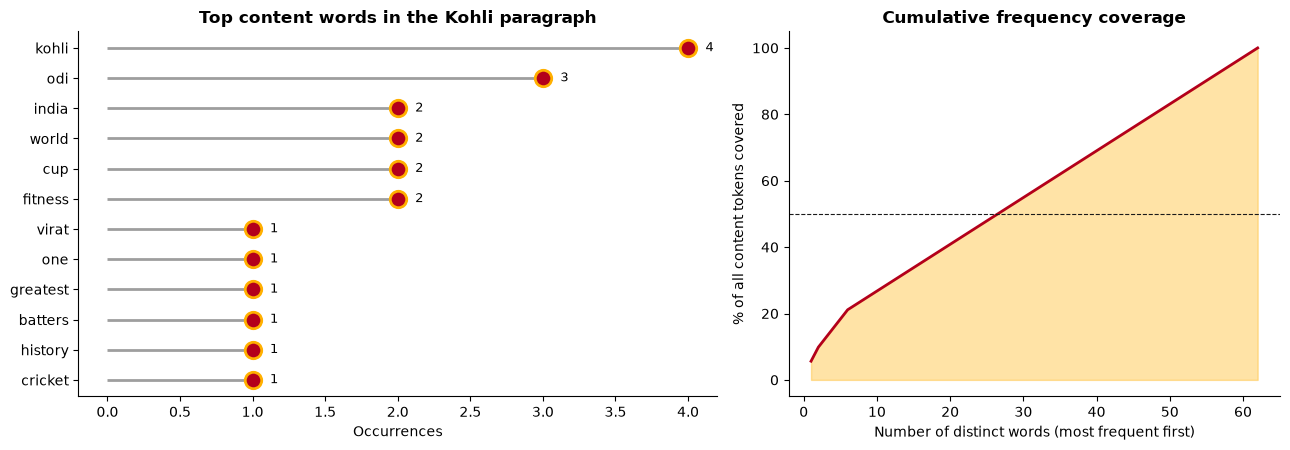

Distinct content words: 62 | words occurring once: 56


In [9]:
fd = FreqDist(content_words)
top12 = pd.DataFrame(fd.most_common(12), columns=["Word", "Count"])
display(top12.T)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})

# (a) lollipop chart of the 12 most common words
y = np.arange(len(top12))[::-1]
ax1.hlines(y, 0, top12["Count"], color=GREY, lw=2)
ax1.scatter(top12["Count"], y, s=140, color=RED, zorder=3, edgecolor=GOLD, lw=2)
ax1.set_yticks(y, top12["Word"])
ax1.set_xlabel("Occurrences")
ax1.set_title("Top content words in the Kohli paragraph")
for xi, yi in zip(top12["Count"], y):
    ax1.text(xi + 0.12, yi, str(xi), va="center", fontsize=9)

# (b) cumulative coverage curve of the full distribution
counts_sorted = np.array(sorted(fd.values(), reverse=True))
coverage = counts_sorted.cumsum() / counts_sorted.sum() * 100
ax2.fill_between(range(1, len(coverage) + 1), coverage, color=GOLD, alpha=0.35)
ax2.plot(range(1, len(coverage) + 1), coverage, color=RED, lw=2)
ax2.axhline(50, ls="--", color=BLACK, lw=0.8)
ax2.set_xlabel("Number of distinct words (most frequent first)")
ax2.set_ylabel("% of all content tokens covered")
ax2.set_title("Cumulative frequency coverage")
plt.tight_layout(); plt.show()

print(f"Distinct content words: {len(fd)} | words occurring once: {len(fd.hapaxes())}")

**Answer (summary):**
- `kohli` is the most frequent content word (4). It is followed by `odi` (3) and then `india`, `world`, `cup` and `fitness` (2 each). Without stopwords, the frequency distribution captures the topic immediately.
- The cumulative curve rises in near-equal steps because most words in a short paragraph occur only once.

---
# Question 2
> **Q2. Using the same paragraph from Q1:**
> 1. Extract all words with only alphabets using `re.findall()`
> 2. Remove stop words using NLTK's stopword list
> 3. Perform stemming with `PorterStemmer`
> 4. Perform lemmatization with `WordNetLemmatizer`
> 5. Compare the stemmed and lemmatized outputs and explain when you'd prefer one over the other.

## Answer 2

### 2.1 Alphabet-only words with `re.findall()`
**Answer:** the pattern `[A-Za-z]+` returns maximal runs of letters, so numbers (`1988`, `50th` → `th`), hyphens and apostrophes act as separators.

In [10]:
alpha_only = re.findall(r"[A-Za-z]+", kohli_para)
alpha_only = [w.lower() for w in alpha_only]
print(f"{len(alpha_only)} alphabetic words found")
print(alpha_only)
print("\nAny digit left?", any(ch.isdigit() for w in alpha_only for ch in w))

126 alphabetic words found
['virat', 'kohli', 'is', 'one', 'of', 'the', 'greatest', 'batters', 'in', 'the', 'history', 'of', 'cricket', 'and', 'his', 'hunger', 'for', 'runs', 'is', 'what', 'sets', 'him', 'apart', 'born', 'in', 'delhi', 'in', 'kohli', 'captained', 'india', 'to', 'the', 'under', 'world', 'cup', 'title', 'in', 'and', 'made', 'his', 'odi', 'debut', 'later', 'that', 'year', 'over', 'the', 'next', 'decade', 'kohli', 'turned', 'chasing', 'into', 'an', 'art', 'his', 'cover', 'drive', 'sharp', 'running', 'between', 'the', 'wickets', 'and', 'calm', 'temperament', 'won', 'india', 'countless', 'matches', 'in', 'the', 'world', 'cup', 'semi', 'final', 'he', 'scored', 'his', 'th', 'odi', 'century', 'breaking', 'sachin', 'tendulkar', 's', 'record', 'of', 'odi', 'centuries', 'he', 'finally', 'lifted', 'the', 'ipl', 'trophy', 'with', 'rcb', 'in', 'after', 'seasons', 'with', 'the', 'same', 'franchise', 'kohli', 's', 'fitness', 'revolution', 'didn', 't', 'just', 'change', 'his', 'own', 'g

### 2.2 Remove stopwords
Fragments such as `s` (from *Tendulkar's*), `t` (from *didn't*) and `th` (from *50th*) are also dropped. `s` and `t` are already in NLTK's list; `th` is removed with a length filter.

In [11]:
q2_words = [w for w in alpha_only if w not in EN_STOP and len(w) > 2]
print(f"{len(q2_words)} words remain:\n{q2_words}")

71 words remain:
['virat', 'kohli', 'one', 'greatest', 'batters', 'history', 'cricket', 'hunger', 'runs', 'sets', 'apart', 'born', 'delhi', 'kohli', 'captained', 'india', 'world', 'cup', 'title', 'made', 'odi', 'debut', 'later', 'year', 'next', 'decade', 'kohli', 'turned', 'chasing', 'art', 'cover', 'drive', 'sharp', 'running', 'wickets', 'calm', 'temperament', 'india', 'countless', 'matches', 'world', 'cup', 'semi', 'final', 'scored', 'odi', 'century', 'breaking', 'sachin', 'tendulkar', 'record', 'odi', 'centuries', 'finally', 'lifted', 'ipl', 'trophy', 'rcb', 'seasons', 'franchise', 'kohli', 'fitness', 'revolution', 'change', 'game', 'raised', 'fitness', 'standards', 'entire', 'indian', 'team']


### 2.3 Stemming with `PorterStemmer`

In [12]:
porter = PorterStemmer()
q2_stems = [porter.stem(w) for w in q2_words]
print(q2_stems)

['virat', 'kohli', 'one', 'greatest', 'batter', 'histori', 'cricket', 'hunger', 'run', 'set', 'apart', 'born', 'delhi', 'kohli', 'captain', 'india', 'world', 'cup', 'titl', 'made', 'odi', 'debut', 'later', 'year', 'next', 'decad', 'kohli', 'turn', 'chase', 'art', 'cover', 'drive', 'sharp', 'run', 'wicket', 'calm', 'tempera', 'india', 'countless', 'match', 'world', 'cup', 'semi', 'final', 'score', 'odi', 'centuri', 'break', 'sachin', 'tendulkar', 'record', 'odi', 'centuri', 'final', 'lift', 'ipl', 'trophi', 'rcb', 'season', 'franchis', 'kohli', 'fit', 'revolut', 'chang', 'game', 'rais', 'fit', 'standard', 'entir', 'indian', 'team']


### 2.4 Lemmatization with `WordNetLemmatizer`
The POS tag of each word is passed to the lemmatizer (verb/adjective/adverb/noun). Without it, every word is treated as a noun and verbs like *captained* or *breaking* stay unchanged.

In [13]:
wnl = WordNetLemmatizer()
POS_MAP = {"J": wordnet.ADJ, "V": wordnet.VERB, "R": wordnet.ADV}

q2_tags = nltk.pos_tag(q2_words)
q2_lemmas_noun = [wnl.lemmatize(w) for w in q2_words]
q2_lemmas = [wnl.lemmatize(w, POS_MAP.get(t[0], wordnet.NOUN)) for w, t in q2_tags]
print("Lemmas (noun default):", q2_lemmas_noun)
print("\nLemmas (with POS)    :", q2_lemmas)

Lemmas (noun default): ['virat', 'kohli', 'one', 'greatest', 'batter', 'history', 'cricket', 'hunger', 'run', 'set', 'apart', 'born', 'delhi', 'kohli', 'captained', 'india', 'world', 'cup', 'title', 'made', 'odi', 'debut', 'later', 'year', 'next', 'decade', 'kohli', 'turned', 'chasing', 'art', 'cover', 'drive', 'sharp', 'running', 'wicket', 'calm', 'temperament', 'india', 'countless', 'match', 'world', 'cup', 'semi', 'final', 'scored', 'odi', 'century', 'breaking', 'sachin', 'tendulkar', 'record', 'odi', 'century', 'finally', 'lifted', 'ipl', 'trophy', 'rcb', 'season', 'franchise', 'kohli', 'fitness', 'revolution', 'change', 'game', 'raised', 'fitness', 'standard', 'entire', 'indian', 'team']

Lemmas (with POS)    : ['virat', 'kohli', 'one', 'great', 'batter', 'history', 'cricket', 'hunger', 'run', 'set', 'apart', 'bear', 'delhi', 'kohli', 'captain', 'india', 'world', 'cup', 'title', 'make', 'odi', 'debut', 'later', 'year', 'next', 'decade', 'kohli', 'turn', 'chase', 'art', 'cover', 'd

### 2.5 Compare stemmed vs lemmatized outputs

,Word,POS,Stem,Lemma,Stem valid?,Lemma valid?
0,greatest,JJS,greatest,great,✔,✔
1,batters,NNS,batter,batter,✔,✔
2,history,NN,histori,history,✘,✔
3,runs,VBZ,run,run,✔,✔
4,sets,NNS,set,set,✔,✔
5,born,VBN,born,bear,✔,✔
6,captained,VBD,captain,captain,✔,✔
7,title,NN,titl,title,✘,✔
8,made,VBD,made,make,✔,✔
9,decade,NN,decad,decade,✘,✔


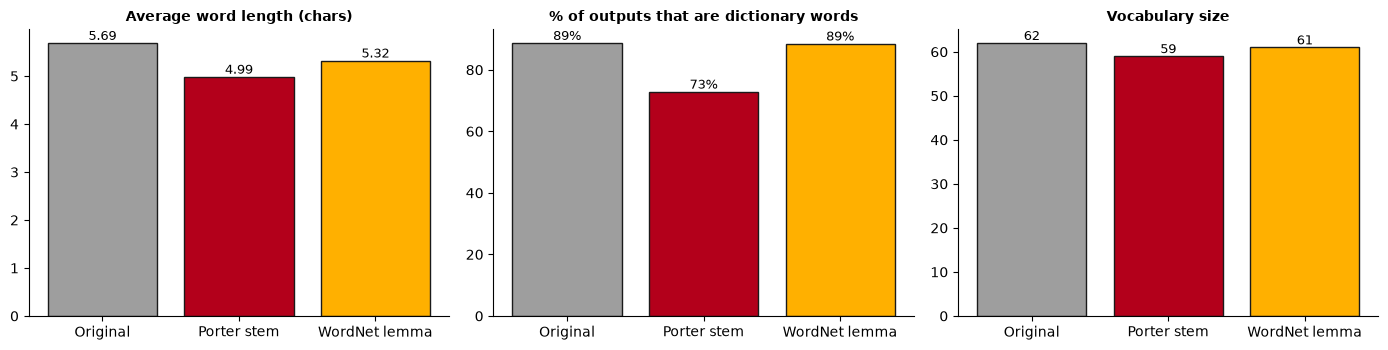

In [14]:
compare_q2 = pd.DataFrame({"Word": q2_words, "POS": [t for _, t in q2_tags],
                           "Stem": q2_stems, "Lemma": q2_lemmas})
compare_q2["Stem valid?"] = compare_q2["Stem"].map(lambda s: "✔" if wordnet.synsets(s) else "✘")
compare_q2["Lemma valid?"] = compare_q2["Lemma"].map(lambda s: "✔" if wordnet.synsets(s) else "✘")
interesting = compare_q2[(compare_q2.Word != compare_q2.Stem) | (compare_q2.Word != compare_q2.Lemma)]
display(interesting.drop_duplicates("Word").reset_index(drop=True))

# Visual: how much each method shortens the words + how many valid words it keeps
avg_len = [np.mean([len(w) for w in s]) for s in (q2_words, q2_stems, q2_lemmas)]
valid = [sum(bool(wordnet.synsets(w)) for w in set(s)) / len(set(s)) * 100 for s in (q2_words, q2_stems, q2_lemmas)]
vocab_sz = [len(set(s)) for s in (q2_words, q2_stems, q2_lemmas)]
labels = ["Original", "Porter stem", "WordNet lemma"]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, vals, title, fmt in zip(axes, (avg_len, valid, vocab_sz),
                                ("Average word length (chars)", "% of outputs that are dictionary words", "Vocabulary size"),
                                ("{:.2f}", "{:.0f}%", "{:d}")):
    bars = ax.bar(labels, vals, color=[GREY, RED, GOLD], edgecolor=BLACK)
    ax.set_title(title, fontsize=10)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), fmt.format(v), ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

**Answer — comparison and when to prefer which**

| Criterion | Stemming (Porter) | Lemmatization (WordNet) |
|---|---|---|
| How it works | Chops suffixes using fixed rules | Looks up the dictionary base form using POS |
| Output quality | Can produce non-words (`history → histori`, `title → titl`, `decade → decad`, `century → centuri`) | Real words (`captained → captain`, `scored → score`, `centuries → century`) |
| `century` vs `centuries` | `centuri` / `centuri` — merged, but unreadable | `century` / `century` — merged **and** readable |
| Speed / resources | Very fast, no dictionary | Slower; needs WordNet and a POS tagger |
| Risk | Over-stemming (unrelated words collapse) | Under-merging if the POS tag is wrong |

- **Prefer stemming** for search engines, document retrieval and quick Bag-of-Words / TF-IDF classifiers. These run on large corpora where speed matters and nobody reads the tokens; matching `run`, `runs` and `running` is enough.
- **Prefer lemmatization** when meaning and readability matter, for example:
  - chatbots and question answering
  - keyword reports and word clouds
  - knowledge-graph extraction
  - any output shown to a human
- On this paragraph the chart shows the trade-off clearly: stemming shortens words the most but drops the share of valid dictionary words, while lemmatization keeps almost all outputs valid.
- **Caveat:** lemmatization is only as good as the POS tag. Here `born` (tagged as a past participle) is lemmatized to `bear`, which is technically correct but not what a reader expects.

---
# Question 3
> **Q3. Choose 3 short texts of your own (e.g., different news headlines, product reviews).**
> 1. Use `CountVectorizer` to generate the Bag of Words representation.
> 2. Use `TfidfVectorizer` to compute TF-IDF scores.
> 3. Print and interpret the top 3 keywords from each text using TF-IDF.

## Answer 3
Three short Kohli news-style texts on **different** themes: a batting record, an IPL title, and fitness.

In [15]:
news = {
    "N1_Record": "Kohli smashes a record 50th ODI century as India beat New Zealand in the World Cup "
                 "semi-final at the Wankhede. The century took Kohli past Sachin Tendulkar, while Shami "
                 "picked up seven wickets.",
    "N2_IPL":    "RCB end an 18-year wait as Kohli finally lifts the IPL trophy. Bengaluru beat Punjab "
                 "Kings in the Ahmedabad final and fans celebrate the title across the city.",
    "N3_Fitness": "Kohli credits a strict fitness routine, a vegetarian diet and early nights for his "
                  "consistency. He says fitness and recovery matter more than talent at the highest level.",
}
for k, v in news.items():
    print(f"{k}: {v}\n")
texts, names = list(news.values()), list(news.keys())

N1_Record: Kohli smashes a record 50th ODI century as India beat New Zealand in the World Cup semi-final at the Wankhede. The century took Kohli past Sachin Tendulkar, while Shami picked up seven wickets.

N2_IPL: RCB end an 18-year wait as Kohli finally lifts the IPL trophy. Bengaluru beat Punjab Kings in the Ahmedabad final and fans celebrate the title across the city.

N3_Fitness: Kohli credits a strict fitness routine, a vegetarian diet and early nights for his consistency. He says fitness and recovery matter more than talent at the highest level.



### 3.1 Bag of Words with `CountVectorizer`
English stopwords are removed and only alphabetic terms are kept (`token_pattern`), so numbers such as `18` and `50th` do not become keywords.

BoW shape (docs x terms): (3, 53)


,ahmedabad,beat,bengaluru,celebrate,century,city,consistency,credits,cup,diet,...,title,took,trophy,vegetarian,wait,wankhede,wickets,world,year,zealand
N1_Record,0,1,0,0,2,0,0,0,1,0,...,0,1,0,0,0,1,1,1,0,1
N2_IPL,1,1,1,1,0,1,0,0,0,0,...,1,0,1,0,1,0,0,0,1,0
N3_Fitness,0,0,0,0,0,0,1,1,0,1,...,0,0,0,1,0,0,0,0,0,0


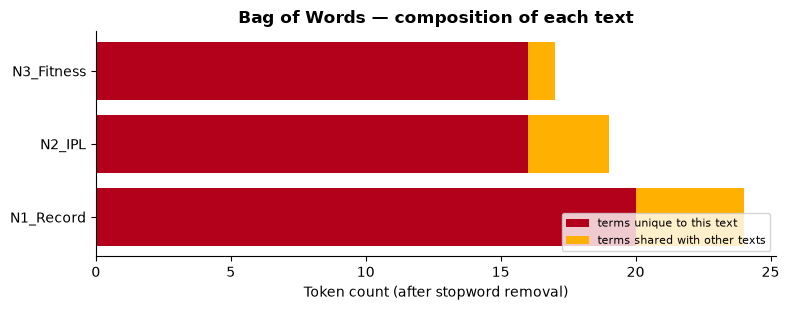

Shared terms: ['beat', 'final', 'kohli']


In [16]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

cv = CountVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{2,}\b")
bow_matrix = cv.fit_transform(texts)
bow_table = pd.DataFrame(bow_matrix.toarray(), index=names, columns=cv.get_feature_names_out())
print("BoW shape (docs x terms):", bow_matrix.shape)
display(bow_table)

# Visual: words per document split into unique vs shared vocabulary
shared_terms = bow_table.columns[(bow_table > 0).sum() > 1]
unique_cnt = [(bow_table.loc[n, bow_table.columns.difference(shared_terms)]).sum() for n in names]
shared_cnt = [(bow_table.loc[n, shared_terms]).sum() for n in names]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(names, unique_cnt, color=RED, label="terms unique to this text")
ax.barh(names, shared_cnt, left=unique_cnt, color=GOLD, label="terms shared with other texts")
ax.set_xlabel("Token count (after stopword removal)")
ax.set_title("Bag of Words — composition of each text")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()
print("Shared terms:", list(shared_terms))

### 3.2 TF-IDF with `TfidfVectorizer`

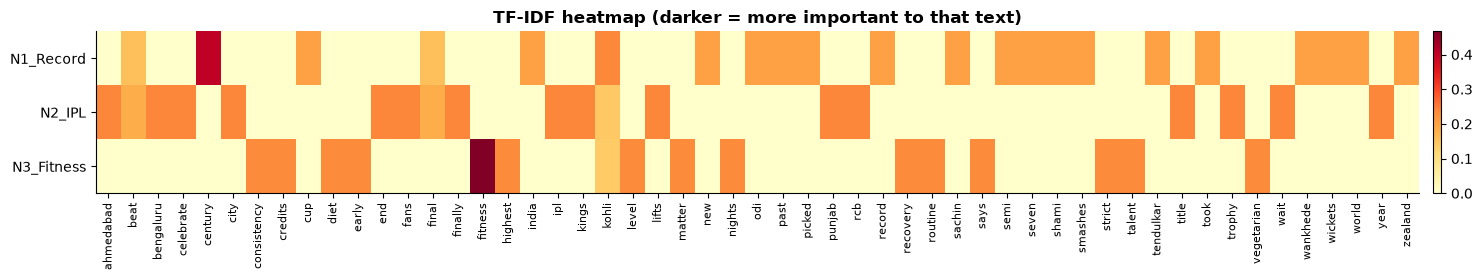

IDF of the most common terms (lower = appears in more texts):
kohli    1.000
final    1.288
beat     1.288
rcb      1.693


In [17]:
tv = TfidfVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{2,}\b")
tfidf_matrix = tv.fit_transform(texts)
terms = tv.get_feature_names_out()
tfidf_table = pd.DataFrame(tfidf_matrix.toarray(), index=names, columns=terms)

# Visual: TF-IDF heatmap (documents x terms)
fig, ax = plt.subplots(figsize=(15, 2.9))
im = ax.imshow(tfidf_table.values, cmap="YlOrRd", aspect="auto")
ax.set_yticks(range(len(names)), names)
ax.set_xticks(range(len(terms)), terms, rotation=90, fontsize=8)
ax.set_title("TF-IDF heatmap (darker = more important to that text)")
fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01)
plt.tight_layout(); plt.show()

idf_view = pd.Series(tv.idf_, index=terms).sort_values()
print("IDF of the most common terms (lower = appears in more texts):")
print(idf_view.head(4).round(3).to_string())

### 3.3 Top 3 keywords per text

In [18]:
def top_k_terms(row_vec, k=3):
    scores = row_vec.toarray().ravel()
    idx = sorted(np.flatnonzero(scores), key=lambda j: (-scores[j], terms[j]))[:k]
    return [(terms[j], round(float(scores[j]), 3)) for j in idx]

top_rows = []
for i, n in enumerate(names):
    for rank, (term, score) in enumerate(top_k_terms(tfidf_matrix[i]), 1):
        top_rows.append({"Text": n, "Rank": rank, "Keyword": term, "TF-IDF": score,
                         "TF (count)": int(bow_table.loc[n, term]),
                         "IDF": round(float(tv.idf_[tv.vocabulary_[term]]), 3)})
top_df = pd.DataFrame(top_rows)
display(top_df.pivot(index="Rank", columns="Text", values="Keyword"))
display(top_df)

Text,N1_Record,N2_IPL,N3_Fitness
Rank,,,
1,century,ahmedabad,fitness
2,kohli,bengaluru,consistency
3,cup,celebrate,credits


,Text,Rank,Keyword,TF-IDF,TF (count),IDF
0,N1_Record,1,century,0.404,2,1.693
1,N1_Record,2,kohli,0.238,2,1.000
2,N1_Record,3,cup,0.202,1,1.693
3,N2_IPL,1,ahmedabad,0.239,1,1.693
4,N2_IPL,2,bengaluru,0.239,1,1.693
5,N2_IPL,3,celebrate,0.239,1,1.693
6,N3_Fitness,1,fitness,0.467,2,1.693
7,N3_Fitness,2,consistency,0.233,1,1.693
8,N3_Fitness,3,credits,0.233,1,1.693


**Interpretation**

- **N1_Record → `century`** is the top keyword. It occurs **twice** in this text and in no other, so both TF and IDF are high; that is exactly what the record story is about.
- **`kohli` is 2nd in N1_Record** because it also occurs twice there. Its score is clearly lower than `century`'s despite the **same count**. That is the IDF effect: `kohli` appears in all three texts (IDF = 1.0), while `century` is unique (IDF ≈ 1.69).
- **N3_Fitness → `fitness`** also appears twice and only here, so it ranks first and correctly identifies the theme.
- **N2_IPL** has no repeated content word, so all its unique terms tie. The top 3 are unique terms from the title story; TF-IDF cannot separate them in such a short text.
- In N2_IPL and N3_Fitness, `kohli` (one occurrence each) falls out of the top 3. TF-IDF rewards what *distinguishes* a document, not what all documents share.
- The same applies to `beat` and `final` (N1 and N2 both have them). Their IDF is lower, so they never rank as keywords.

---
# Question 4
> **Q4. Write 2 short texts (4–6 lines each) describing two different technologies (e.g., AI vs Blockchain).**
> 1. Preprocess and tokenize both texts.
> 2. Calculate:
>    a. Jaccard Similarity using sets
>    b. Cosine Similarity using `TfidfVectorizer` + `cosine_similarity()`
>    c. Analyze which similarity metric gives better insights in your case.

## Answer 4
Two technologies from modern cricket, both linked to Kohli: **DRS / Hawk-Eye ball-tracking** vs **wearable GPS fitness tracking**.

In [19]:
tech_drs = (
    "The Decision Review System lets teams challenge an umpire's call during a cricket match.\n"
    "Hawk-Eye uses multiple high-speed cameras to track the ball and predict its path to the stumps.\n"
    "UltraEdge uses sound and video to detect whether the ball touched the bat.\n"
    "Captains like Virat Kohli have used reviews to overturn close lbw decisions.\n"
    "The technology makes umpiring fairer but still relies on human judgement for marginal calls."
)
tech_gps = (
    "Wearable GPS vests track how far a player runs and how fast they sprint during training.\n"
    "Heart-rate sensors and accelerometers measure workload and fatigue in real time.\n"
    "Sports scientists use this data to plan recovery and reduce the risk of injury.\n"
    "Fitness-focused players like Virat Kohli rely on such data to stay match-ready across formats.\n"
    "The technology turns training into a measurable process instead of guesswork."
)
print("TEXT 1 — DRS / Hawk-Eye\n" + tech_drs)
print("\nTEXT 2 — Wearable GPS tracking\n" + tech_gps)

TEXT 1 — DRS / Hawk-Eye
The Decision Review System lets teams challenge an umpire's call during a cricket match.
Hawk-Eye uses multiple high-speed cameras to track the ball and predict its path to the stumps.
UltraEdge uses sound and video to detect whether the ball touched the bat.
Captains like Virat Kohli have used reviews to overturn close lbw decisions.
The technology makes umpiring fairer but still relies on human judgement for marginal calls.

TEXT 2 — Wearable GPS tracking
Wearable GPS vests track how far a player runs and how fast they sprint during training.
Heart-rate sensors and accelerometers measure workload and fatigue in real time.
Sports scientists use this data to plan recovery and reduce the risk of injury.
Fitness-focused players like Virat Kohli rely on such data to stay match-ready across formats.
The technology turns training into a measurable process instead of guesswork.


### 4.1 Preprocess and tokenize
**Steps:**
1. Lowercase.
2. Regex to keep letters only.
3. `word_tokenize`.
4. Remove stopwords and 1-letter tokens.
5. POS-aware lemmatization, so that `uses/use`, `players/player` and `tracks/track` match across the texts.

In [20]:
def clean_tokens(text: str) -> list[str]:
    text = re.sub(r"[^a-z]+", " ", text.lower())
    toks = [t for t in word_tokenize(text) if t not in EN_STOP and len(t) > 1]
    return [wnl.lemmatize(w, POS_MAP.get(tag[0], wordnet.NOUN)) for w, tag in nltk.pos_tag(toks)]

toks_drs, toks_gps = clean_tokens(tech_drs), clean_tokens(tech_gps)
print(f"DRS tokens ({len(toks_drs)}):", toks_drs)
print(f"\nGPS tokens ({len(toks_gps)}):", toks_gps)

DRS tokens (51): ['decision', 'review', 'system', 'let', 'team', 'challenge', 'umpire', 'call', 'cricket', 'match', 'hawk', 'eye', 'use', 'multiple', 'high', 'speed', 'camera', 'track', 'ball', 'predict', 'path', 'stump', 'ultraedge', 'us', 'sound', 'video', 'detect', 'whether', 'ball', 'touch', 'bat', 'captain', 'like', 'virat', 'kohli', 'use', 'review', 'overturn', 'close', 'lbw', 'decision', 'technology', 'make', 'umpiring', 'fairer', 'still', 'rely', 'human', 'judgement', 'marginal', 'call']

GPS tokens (48): ['wearable', 'gps', 'vest', 'track', 'far', 'player', 'run', 'fast', 'sprint', 'train', 'heart', 'rate', 'sensor', 'accelerometer', 'measure', 'workload', 'fatigue', 'real', 'time', 'sport', 'scientist', 'use', 'data', 'plan', 'recovery', 'reduce', 'risk', 'injury', 'fitness', 'focus', 'player', 'like', 'virat', 'kohli', 'rely', 'data', 'stay', 'match', 'ready', 'across', 'format', 'technology', 'turn', 'train', 'measurable', 'process', 'instead', 'guesswork']


### 4.2 (a) Jaccard similarity using sets
$$J(A,B)=\frac{|A\cap B|}{|A\cup B|}$$

|A| = 46   |B| = 45   |A ∩ B| = 8   |A ∪ B| = 83
Shared words: ['kohli', 'like', 'match', 'rely', 'technology', 'track', 'use', 'virat']
Jaccard = 8 / 83 = 0.0964


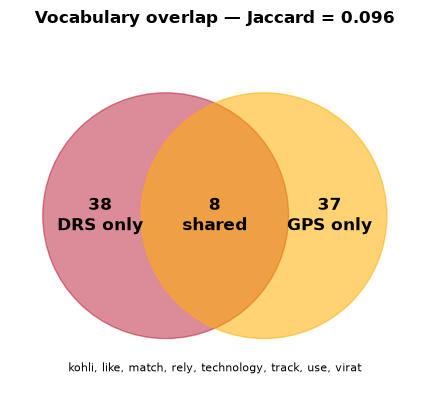

In [21]:
A, B = set(toks_drs), set(toks_gps)
common, combined = A & B, A | B
jac = len(common) / len(combined)

print(f"|A| = {len(A)}   |B| = {len(B)}   |A ∩ B| = {len(common)}   |A ∪ B| = {len(combined)}")
print("Shared words:", sorted(common))
print(f"Jaccard = {len(common)} / {len(combined)} = {jac:.4f}")

# Visual: Venn diagram drawn with matplotlib circles
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.add_patch(Circle((0.38, 0.5), 0.30, color=RED, alpha=0.45))
ax.add_patch(Circle((0.62, 0.5), 0.30, color=GOLD, alpha=0.55))
ax.text(0.22, 0.5, f"{len(A - B)}\nDRS only", ha="center", va="center", fontsize=12, weight="bold")
ax.text(0.78, 0.5, f"{len(B - A)}\nGPS only", ha="center", va="center", fontsize=12, weight="bold")
ax.text(0.50, 0.5, f"{len(common)}\nshared", ha="center", va="center", fontsize=12, weight="bold")
ax.text(0.50, 0.12, ", ".join(sorted(common)), ha="center", fontsize=8, wrap=True)
ax.set_xlim(0, 1); ax.set_ylim(0.05, 0.95); ax.set_aspect("equal"); ax.axis("off")
ax.set_title(f"Vocabulary overlap — Jaccard = {jac:.3f}")
plt.tight_layout(); plt.show()

### 4.2 (b) Cosine similarity with `TfidfVectorizer` + `cosine_similarity()`
$$\cos\theta=\frac{\vec a\cdot\vec b}{\lVert\vec a\rVert\lVert\vec b\rVert}$$

In [22]:
from sklearn.metrics.pairwise import cosine_similarity

tv2 = TfidfVectorizer()
vecs = tv2.fit_transform([" ".join(toks_drs), " ".join(toks_gps)])
cos = float(cosine_similarity(vecs)[0, 1])

contrib = pd.DataFrame(vecs.toarray().T, index=tv2.get_feature_names_out(), columns=["DRS", "GPS"])
contrib = contrib[(contrib.DRS > 0) & (contrib.GPS > 0)]
contrib["DRS×GPS"] = contrib.DRS * contrib.GPS
contrib = contrib.sort_values("DRS×GPS", ascending=False).round(4)
display(contrib)
print(f"Sum of products (= cosine, vectors are L2-normalised): {contrib['DRS×GPS'].sum():.4f}")
print(f"Cosine similarity = {cos:.4f}")

# Cosine on raw, unprocessed text for comparison
cos_raw = float(cosine_similarity(TfidfVectorizer().fit_transform([tech_drs, tech_gps]))[0, 1])
print(f"Cosine on raw text (no preprocessing) = {cos_raw:.4f}")

,DRS,GPS,DRS×GPS
use,0.1909,0.1006,0.0192
kohli,0.0954,0.1006,0.0096
like,0.0954,0.1006,0.0096
match,0.0954,0.1006,0.0096
rely,0.0954,0.1006,0.0096
technology,0.0954,0.1006,0.0096
track,0.0954,0.1006,0.0096
virat,0.0954,0.1006,0.0096


Sum of products (= cosine, vectors are L2-normalised): 0.0864
Cosine similarity = 0.0864
Cosine on raw text (no preprocessing) = 0.2261


### 4.2 (c) Which metric gives better insight?

,Metric,Score
0,Jaccard (sets),0.0964
1,Cosine TF-IDF (preprocessed),0.0864
2,Cosine TF-IDF (raw text),0.2261


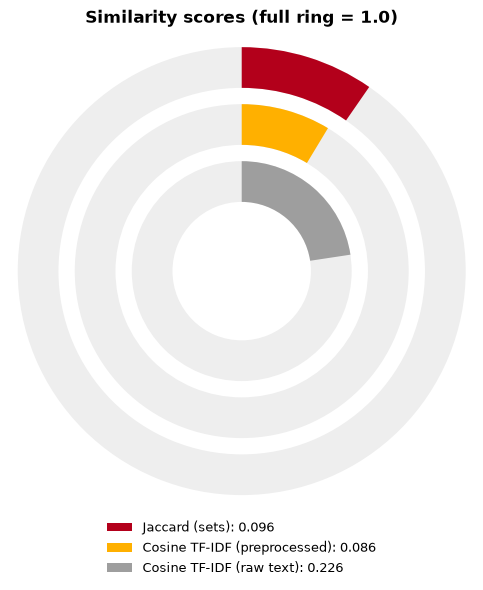

In [23]:
metrics = pd.DataFrame({
    "Metric": ["Jaccard (sets)", "Cosine TF-IDF (preprocessed)", "Cosine TF-IDF (raw text)"],
    "Score": [jac, cos, cos_raw],
})
display(metrics.round(4))

# Visual: radial gauge-style comparison
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={"projection": "polar"})
colors = [RED, GOLD, GREY]
for i, (m, s) in enumerate(zip(metrics.Metric, metrics.Score)):
    r = 1.0 - i * 0.28
    ax.barh(r, np.pi * 2, height=0.2, left=0, color="#EEEEEE")
    ax.barh(r, s * np.pi * 2, height=0.2, left=0, color=colors[i], label=f"{m}: {s:.3f}")
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
ax.set_xticks([]); ax.set_yticks([]); ax.spines["polar"].set_visible(False)
ax.set_title("Similarity scores (full ring = 1.0)", pad=12)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.18), fontsize=9, frameon=False)
plt.tight_layout(); plt.show()

**Analysis**

1. Both metrics give a **low** score (Jaccard ≈ 0.096, cosine ≈ 0.086), which matches reality: ball-tracking for umpiring and GPS fitness tracking are different technologies. They share only 8 context words: `kohli`, `like`, `match`, `rely`, `technology`, `track`, `use`, `virat`.
2. **Jaccard** treats every shared word as equally important. `like` counts exactly as much as `track`, and repeated words carry no extra weight. It only measures vocabulary overlap.
3. **Cosine + TF-IDF** weights words by frequency and normalises for text length. Its contribution table shows *which* shared words drive the similarity, which Jaccard cannot do. Words repeated within a text (e.g. `data` and `player` in the GPS text, `ball` and `call` in the DRS text) increase that text's vector norm and correctly dilute the overlap.
4. Cosine comes out slightly **below** Jaccard here. Each text repeats its own technical words (`ball`, `call`, `review`, `decision` vs `data`, `player`, `train`), so most of each vector's weight sits on words the other text does not have. That is the correct reading: the shared words are incidental.
5. **Preprocessing matters.**
   - On raw text the cosine score jumps to ≈ 0.23 because both texts share `the`, `to`, `and`, `a`. That inflated number would be misleading.
   - Lemmatization lets `players`/`player` match.
   - One honest flaw: the POS tagger read `UltraEdge uses` as a noun, so `uses` was lemmatized to `us`. Automatic preprocessing can introduce small errors.

**Conclusion:** for this pair, **cosine similarity on TF-IDF vectors gives the better insight**. It is explainable term by term, robust to repetition and length, and it is the metric that scales to ranking many documents. Jaccard is still a useful, simple sanity check of how many words two texts share; it is best suited to short sets such as tags or keywords.

**Limitation both share:** neither metric understands meaning. A semantic embedding model (e.g. sentence-transformers) would be needed to see that *Hawk-Eye tracks the ball* and *GPS tracks the player* use `track` in related but different senses.

---
# Question 5
> **Q5. Write a short review for a product or service.**
> 1. Use TextBlob or VADER to find polarity & subjectivity for each review.
> 2. Classify reviews into Positive / Negative / Neutral.
> 3. Create a word cloud using the `wordcloud` library for all positive reviews.

## Answer 5
**Service reviewed:** the live match-day experience of watching Virat Kohli bat at the stadium. Eight short fan reviews.

In [24]:
fan_reviews = [
    "Watching Kohli's cover drive live was pure magic! The crowd chanting his name gave me goosebumps.",
    "Waited four hours in the heat and Kohli got out for a duck. Overpriced food and terrible queues.",
    "Brilliant century by Kohli, superb atmosphere and smooth entry gates. Totally worth the ticket price.",
    "The match started at 7:30 pm and Kohli opened the batting with Faf.",
    "Seats were cramped, the screen was broken and the parking was a nightmare. Very disappointing day.",
    "Kohli's chase masterclass was unforgettable. Best evening of my life, loved every single shot!",
    "Decent game but Kohli scored only 20, and the stands were too noisy to enjoy it properly.",
    "The stadium staff were helpful and polite, and the new food court is excellent.",
]
print(len(fan_reviews), "reviews loaded")

8 reviews loaded


### 5.1 Polarity and subjectivity
- **TextBlob** gives `polarity` (−1 to +1) and `subjectivity` (0 = factual, 1 = opinion).
- **VADER** gives `neg/neu/pos` proportions and a normalised `compound` score (−1 to +1). It handles `!`, CAPS, intensifiers and negation, which suits informal fan reviews.

In [25]:
from textblob import TextBlob
from nltk.sentiment.vader import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()
rows = []
for i, rev in enumerate(fan_reviews, 1):
    blob = TextBlob(rev)
    v = sia.polarity_scores(rev)
    rows.append({"ID": f"F{i}", "Review": rev,
                 "Polarity (TB)": round(blob.sentiment.polarity, 3),
                 "Subjectivity (TB)": round(blob.sentiment.subjectivity, 3),
                 "neg": v["neg"], "neu": v["neu"], "pos": v["pos"],
                 "Compound (VADER)": v["compound"]})
rev_df = pd.DataFrame(rows)
display(rev_df)

,ID,Review,Polarity (TB),Subjectivity (TB),neg,neu,pos,Compound (VADER)
0,F1,Watching Kohli's cover drive live was pure mag...,0.325,0.667,0.000,1.000,0.000,0.0000
1,F2,Waited four hours in the heat and Kohli got ou...,-1.000,1.000,0.162,0.838,0.000,-0.4767
2,F3,"Brilliant century by Kohli, superb atmosphere ...",0.650,0.650,0.000,0.543,0.457,0.8777
3,F4,The match started at 7:30 pm and Kohli opened ...,0.000,0.000,0.000,1.000,0.000,0.0000
4,F5,"Seats were cramped, the screen was broken and ...",-0.590,0.655,0.336,0.664,0.000,-0.7645
5,F6,Kohli's chase masterclass was unforgettable. B...,0.603,0.579,0.000,0.588,0.412,0.8553
6,F7,"Decent game but Kohli scored only 20, and the ...",0.033,0.533,0.096,0.703,0.201,0.5023
7,F8,"The stadium staff were helpful and polite, and...",0.568,0.727,0.000,0.649,0.351,0.7579


### 5.2 Classify as Positive / Negative / Neutral
**Rule:** a score ≥ +0.05 → Positive, ≤ −0.05 → Negative, otherwise Neutral. The rule is applied to VADER `compound` and to TextBlob `polarity` separately.

**Final label (simple ensemble):**
- If the two tools agree, that label is used.
- If they disagree, the label comes from whichever tool gives the stronger signal (larger absolute score). This avoids blindly trusting one lexicon.

,ID,Review,Polarity (TB),Subjectivity (TB),Compound (VADER),TextBlob class,VADER class,Sentiment
0,F1,Watching Kohli's cover drive live was pure mag...,0.325,0.667,0.0000,Positive,Neutral,Positive
1,F2,Waited four hours in the heat and Kohli got ou...,-1.000,1.000,-0.4767,Negative,Negative,Negative
2,F3,"Brilliant century by Kohli, superb atmosphere ...",0.650,0.650,0.8777,Positive,Positive,Positive
3,F4,The match started at 7:30 pm and Kohli opened ...,0.000,0.000,0.0000,Neutral,Neutral,Neutral
4,F5,"Seats were cramped, the screen was broken and ...",-0.590,0.655,-0.7645,Negative,Negative,Negative
5,F6,Kohli's chase masterclass was unforgettable. B...,0.603,0.579,0.8553,Positive,Positive,Positive
6,F7,"Decent game but Kohli scored only 20, and the ...",0.033,0.533,0.5023,Neutral,Positive,Positive
7,F8,"The stadium staff were helpful and polite, and...",0.568,0.727,0.7579,Positive,Positive,Positive


Sentiment
Positive    5
Neutral     1
Negative    2
TextBlob/VADER agreement: 6 / 8


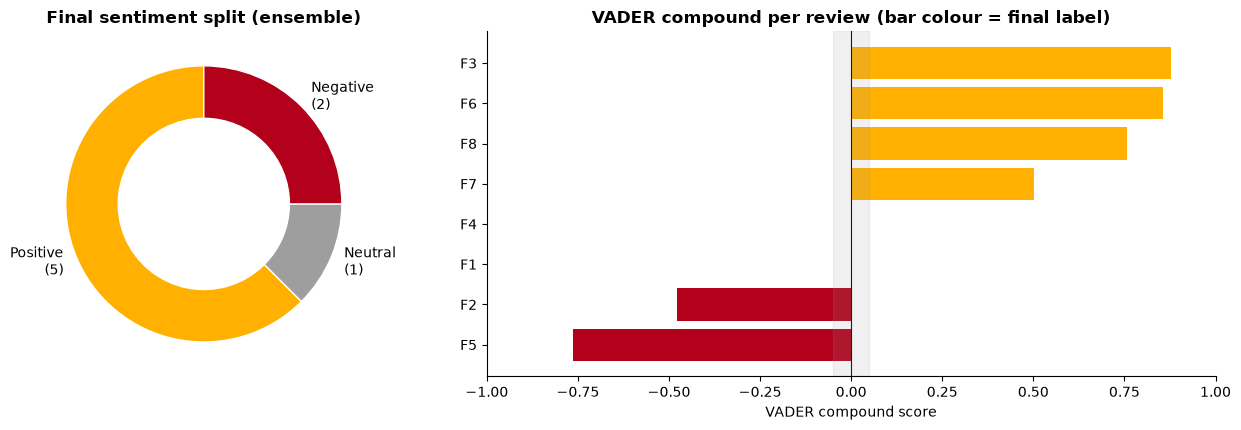

In [26]:
def classify(score, cut=0.05):
    return "Positive" if score >= cut else "Negative" if score <= -cut else "Neutral"

rev_df["TextBlob class"] = rev_df["Polarity (TB)"].map(classify)
rev_df["VADER class"] = rev_df["Compound (VADER)"].map(classify)
# Final label: if both tools agree, keep it; otherwise trust the tool with the stronger (larger |score|) signal
rev_df["Sentiment"] = np.where(
    rev_df["TextBlob class"] == rev_df["VADER class"], rev_df["VADER class"],
    np.where(rev_df["Polarity (TB)"].abs() > rev_df["Compound (VADER)"].abs(),
             rev_df["TextBlob class"], rev_df["VADER class"]))
display(rev_df[["ID", "Review", "Polarity (TB)", "Subjectivity (TB)", "Compound (VADER)",
                "TextBlob class", "VADER class", "Sentiment"]])

dist = rev_df["Sentiment"].value_counts().reindex(["Positive", "Neutral", "Negative"], fill_value=0)
print(dist.to_string())
print("TextBlob/VADER agreement:", (rev_df["TextBlob class"] == rev_df["VADER class"]).sum(), "/", len(rev_df))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.6]})
# (a) donut chart of the class distribution
ax1.pie(dist.values, labels=[f"{k}\n({v})" for k, v in dist.items()], colors=[GOLD, GREY, RED],
        startangle=90, wedgeprops={"width": 0.38, "edgecolor": "white"})
ax1.set_title("Final sentiment split (ensemble)")
# (b) diverging bar of compound score per review
order = rev_df.sort_values("Compound (VADER)")
ax2.barh(order["ID"], order["Compound (VADER)"],
         color=[{"Positive": GOLD, "Negative": RED, "Neutral": GREY}[c] for c in order["Sentiment"]])
ax2.axvline(0, color=BLACK, lw=0.8)
ax2.axvspan(-0.05, 0.05, color=GREY, alpha=0.15)
ax2.set_xlim(-1, 1); ax2.set_xlabel("VADER compound score")
ax2.set_title("VADER compound per review (bar colour = final label)")
plt.tight_layout(); plt.show()

### 5.3 Word cloud of all positive reviews
Drawn inside a **circular (cricket-ball) mask** with a red–gold colour scheme.

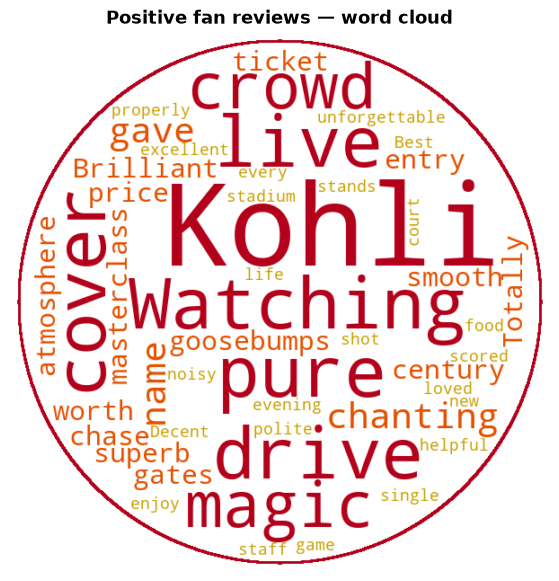

Saved waris_q5_positive_wordcloud.png
Most prominent words: ['Kohli', 'Watching', 'cover', 'drive', 'live', 'pure', 'magic', 'crowd']


In [27]:
from wordcloud import WordCloud, STOPWORDS

pos_text = " ".join(rev_df.loc[rev_df["Sentiment"] == "Positive", "Review"])
if not pos_text:
    print("No positive reviews to visualise.")
else:
    size = 600
    yy, xx = np.ogrid[:size, :size]
    ball_mask = ((xx - size / 2) ** 2 + (yy - size / 2) ** 2 > (size / 2 - 10) ** 2).astype(np.uint8) * 255

    def rcb_colors(word, font_size, position, orientation, random_state=None, **kw):
        return RED if font_size > 40 else "#E65100" if font_size > 25 else "#C9A000"

    cloud = WordCloud(width=size, height=size, background_color="white", mask=ball_mask,
                      contour_width=4, contour_color=RED, stopwords=STOPWORDS | EN_STOP,
                      color_func=rcb_colors, max_words=70, random_state=7, prefer_horizontal=0.85
                      ).generate(pos_text)
    plt.figure(figsize=(7, 7))
    plt.imshow(cloud, interpolation="bilinear"); plt.axis("off")
    plt.title("Positive fan reviews — word cloud", fontsize=13, weight="bold")
    plt.show()
    cloud.to_file("waris_q5_positive_wordcloud.png")
    print("Saved waris_q5_positive_wordcloud.png")
    print("Most prominent words:", [w for w, _ in sorted(cloud.words_.items(), key=lambda kv: -kv[1])[:8]])

**Answer (observations)**
- **F4** (*"The match started at 7:30 pm…"*) is a pure statement of fact: polarity 0, subjectivity 0, compound 0. Both tools classify it **Neutral**.
- **F1** (*"…pure magic! … goosebumps"*) is clearly positive, but **VADER scores it 0.0**: none of its words are in VADER's lexicon. TextBlob catches it (polarity ≈ +0.33), and the ensemble rule rescues the label to Positive. Relying on VADER alone would have mislabelled it Neutral.
- **F7** (*"Decent game but Kohli scored only 20…"*) is a genuinely mixed review.
  - VADER says positive (≈ +0.50, from `decent` and `enjoy`); TextBlob says neutral (≈ +0.03).
  - A human would call it neutral or mixed. Lexicon methods simply add word scores and cannot read `but` the way a person does.
- Strongly emotional reviews (F2, F3, F6) have high subjectivity: they express personal experience, not facts.
- The word cloud shows what fans value most: **Kohli**, his batting, the atmosphere and the overall experience.

---
# Question 6
> **Q6. Choose your own paragraph (~100 words) as training data.**
> 1. Tokenize text using `Tokenizer()` from `keras.preprocessing.text`
> 2. Create input sequences and build a simple LSTM or Dense model
> 3. Train the model and generate 2–3 new lines of text starting from any seed word you provide.

## Answer 6
**Training paragraph (~100 words) about Kohli's batting.**

In [28]:
import os, random
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf

try:
    from tensorflow.keras.preprocessing.text import Tokenizer
except ImportError:
    from tf_keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import pad_sequences, to_categorical
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

random.seed(11); np.random.seed(11); tf.random.set_seed(11)

train_text = (
    "virat kohli walks out to bat with the same hunger every time. "
    "he watches the ball closely and plays it late. "
    "the cover drive is his favourite shot and the crowd rises every time he plays it. "
    "kohli loves the chase because the target gives him a clear plan. "
    "he rotates the strike, runs hard between the wickets and waits for the loose ball. "
    "when the pressure rises, kohli stays calm and finishes the game. "
    "his fitness, discipline and hunger for runs make him a champion. "
    "every young cricketer in india dreams of batting like virat kohli."
)
print("Word count:", len(train_text.split()))

Word count: 97


### 6.1 Tokenize with `Tokenizer()`

In [29]:
sentences6 = [s.strip() for s in train_text.split(".") if s.strip()]
tok = Tokenizer()
tok.fit_on_texts(sentences6)
V = len(tok.word_index) + 1

print(f"Sentences: {len(sentences6)} | vocabulary size (with padding id 0): {V}")
word_counts = pd.Series(dict(tok.word_counts)).sort_values(ascending=False)
display(pd.DataFrame({"word": word_counts.index[:10], "count": word_counts.values[:10],
                      "token id": [tok.word_index[w] for w in word_counts.index[:10]]}).T)

Sentences: 8 | vocabulary size (with padding id 0): 65


,0,1,2,3,4,5,6,7,8,9
word,the,and,kohli,he,every,for,his,rises,runs,it
count,11,5,4,3,3,2,2,2,2,2
token id,1,2,3,5,4,17,12,13,16,11


### 6.2 Create input sequences and build the LSTM model
Each sentence produces all of its prefixes of length ≥ 2. The last token of a prefix is the label (next word) and the rest is the left-padded input.

In [30]:
seqs = []
for s in sentences6:
    ids = tok.texts_to_sequences([s])[0]
    seqs += [ids[: n + 1] for n in range(1, len(ids))]

L = max(map(len, seqs))
seqs = pad_sequences(seqs, maxlen=L, padding="pre")
X6, y6_ids = seqs[:, :-1], seqs[:, -1]
y6 = to_categorical(y6_ids, num_classes=V)
print(f"{len(seqs)} training pairs | input length {L - 1} | X {X6.shape} | y {y6.shape}")

inv = tok.index_word
display(pd.DataFrame({"context": [" ".join(inv[t] for t in r if t) for r in X6[5:10]],
                      "next word": [inv[t] for t in y6_ids[5:10]]}))

lm = Sequential([
    Input(shape=(L - 1,)),
    Embedding(V, 100),
    LSTM(128, return_sequences=True),
    LSTM(64),
    Dense(V, activation="softmax"),
], name="kohli_lstm")
lm.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
           loss="categorical_crossentropy", metrics=["accuracy"])
lm.summary()

89 training pairs | input length 15 | X (89, 15) | y (89, 65)


,context,next word
0,virat kohli walks out to bat,with
1,virat kohli walks out to bat with,the
2,virat kohli walks out to bat with the,same
3,virat kohli walks out to bat with the same,hunger
4,virat kohli walks out to bat with the same hunger,every


Model: "kohli_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 15, 100)        │         6,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 15, 128)        │       117,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 65)             │         4,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 177,381 (692.89 KB)

 Trainable params: 177,381 (692.89 KB)

 Non-trainable params: 0 (0.00 B)

### 6.3 Train and generate new lines
Two stacked LSTMs with a higher learning rate (0.01). Training stops early once loss stops improving.

Epochs run: 200 | final loss 0.0186 | final accuracy 97.75%


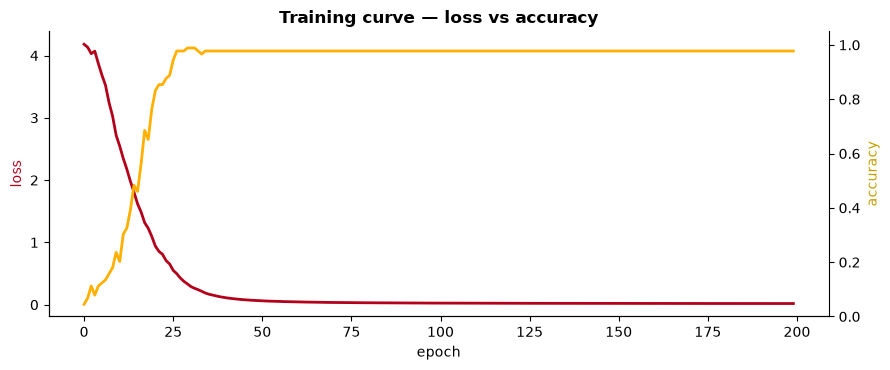

In [31]:
hist = lm.fit(X6, y6, epochs=200, batch_size=32, verbose=0,
              callbacks=[EarlyStopping(monitor="loss", patience=15, restore_best_weights=True)])
loss_h, acc_h = hist.history["loss"], hist.history["accuracy"]
print(f"Epochs run: {len(loss_h)} | final loss {loss_h[-1]:.4f} | final accuracy {acc_h[-1]:.2%}")

# Visual: single dual-axis training chart
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(loss_h, color=RED, lw=2, label="loss"); ax.set_ylabel("loss", color=RED); ax.set_xlabel("epoch")
ax2 = ax.twinx(); ax2.plot(acc_h, color=GOLD, lw=2, label="accuracy")
ax2.set_ylabel("accuracy", color="#C9A000"); ax2.set_ylim(0, 1.05)
ax2.spines["right"].set_visible(True)
ax.set_title("Training curve — loss vs accuracy")
plt.tight_layout(); plt.show()

,Seed,Greedy line,Top-3 sampled line
0,kohli,kohli loves the chase because the target gives...,kohli loves the chase because the target gives...
1,the chase,the chase drive is his favourite shot and the ...,the chase cover drive his and shot and plays i...
2,india,india young young cricketer in india dreams of...,india young young in india india dreams of bat...



Generated lines:
  • kohli loves the chase because the target gives him a
  • kohli loves the chase because the target gives him a
  • the chase drive is his favourite shot and the crowd rises
  • the chase cover drive his and shot and plays it he
  • india young young cricketer in india dreams of batting like
  • india young young in india india dreams of batting like


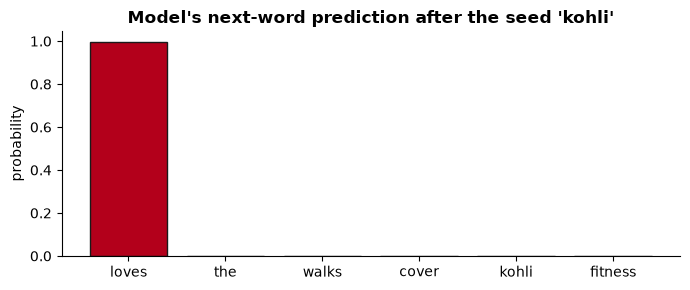

In [32]:
def next_word_probs(context: str):
    ids = pad_sequences([tok.texts_to_sequences([context])[0]], maxlen=L - 1, padding="pre")
    p = lm.predict(ids, verbose=0)[0]
    p[0] = 0
    return p / p.sum()

def write_line(seed: str, length: int = 9, top_k: int | None = None) -> str:
    out = seed.lower()
    for _ in range(length):
        p = next_word_probs(out)
        if top_k:                                  # top-k sampling with temperature 2 for variety
            cand = np.argsort(p)[::-1][:top_k]
            w = p[cand] ** 0.5
            nxt = int(np.random.choice(cand, p=w / w.sum()))
        else:                                      # greedy
            nxt = int(np.argmax(p))
        out += " " + inv[nxt]
    return out

np.random.seed(11)
seed_words = ["kohli", "the chase", "india"]
lines = pd.DataFrame([{"Seed": s, "Greedy line": write_line(s), "Top-3 sampled line": write_line(s, top_k=3)}
                      for s in seed_words])
display(lines)
print("\nGenerated lines:")
for _, r in lines.iterrows():
    print(f"  • {r['Greedy line']}")
    print(f"  • {r['Top-3 sampled line']}")

# Visual: what does the model believe comes after "kohli"?
p = next_word_probs("kohli")
best = np.argsort(p)[::-1][:6]
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar([inv[i] for i in best], p[best], color=[RED] + [GOLD] * 5, edgecolor=BLACK)
ax.set_ylabel("probability"); ax.set_title("Model's next-word prediction after the seed 'kohli'")
plt.tight_layout(); plt.show()

**Answer (discussion)**
- `Tokenizer()` built a vocabulary from the paragraph. Every sentence was expanded into n-gram prefixes, and a stacked **Embedding → LSTM(128) → LSTM(64) → Dense(softmax)** model learned to predict the next word.
- With only ~100 words of data the network **memorises** the paragraph, as the near-100% training accuracy shows. Greedy decoding therefore mostly replays training phrases.
- **Top-3 sampling** (temperature 2) picks randomly among the three most likely words. This lets the model jump between sentences that share a word (*kohli*, *the*, *every*, *hunger*), producing lines that are not copied verbatim. It also shows a classic small-model failure: sampling can loop on a very frequent word (`and and and`), which is why practical generators add repetition penalties.
- The seed **india** appears only once, near the end of the paragraph, so the model has little context there. That is where the output becomes least grammatical.
- A larger corpus, validation data and pretrained embeddings (or a transformer) are needed for genuinely new, fluent text.

---
## Summary of answers
| Q | Task | Key answer |
|---|---|---|
| 1 | Clean, tokenize, compare `split()` vs `word_tokenize()`, stopwords, frequency | `word_tokenize` separates punctuation and contractions; `kohli` is the top content word |
| 2 | Regex words, stopwords, stemming vs lemmatization | Lemmas stay valid words (`centuries → century`), stems often don't (`histori`) |
| 3 | BoW, TF-IDF, top-3 keywords | `century` and `fitness` top their texts; `kohli` gets the lowest IDF because it's in every text |
| 4 | Jaccard vs Cosine for DRS vs GPS wearables | Both low; cosine + TF-IDF is more informative and explainable |
| 5 | TextBlob + VADER sentiment, classes, word cloud | 8 fan reviews classified; ball-shaped word cloud of positive reviews |
| 6 | Keras Tokenizer → stacked LSTM → text generation | Model trained; 3 seeds × greedy and top-3 sampling lines generated |